# Student Performance Prediction
Run the cells in order. This notebook uses the same simple structure as the sample project: dataset, demo.py, model file and Streamlit app.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

## 1. Load dataset and inspect using pandas

In [6]:
data = pd.read_csv("student_data.csv")
data.head()

,Study_Hours,Attendance,Previous_Score,Sleep_Hours,Assignment_Average,Practice_Tests,Internet_Access,Parent_Education,Extracurricular,Final_Score
0,4.0,81.3,61.7,8.5,81.8,3,Yes,Postgraduate,No,92.3
1,1.8,73.2,58.7,7.8,91.4,0,Yes,School,No,70.0
2,4.7,77.0,74.1,9.4,82.1,4,Yes,College,No,99.4
3,5.0,89.6,71.5,5.1,100.0,1,Yes,College,No,94.6
4,0.4,82.0,48.3,6.7,99.4,3,Yes,School,Yes,87.7


In [7]:
print("Shape:", data.shape)
print(data.info())
data.describe()

Shape: (1000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Study_Hours         1000 non-null   float64
 1   Attendance          1000 non-null   float64
 2   Previous_Score      1000 non-null   float64
 3   Sleep_Hours         1000 non-null   float64
 4   Assignment_Average  1000 non-null   float64
 5   Practice_Tests      1000 non-null   int64  
 6   Internet_Access     1000 non-null   object 
 7   Parent_Education    1000 non-null   object 
 8   Extracurricular     1000 non-null   object 
 9   Final_Score         1000 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 78.3+ KB
None


,Study_Hours,Attendance,Previous_Score,Sleep_Hours,Assignment_Average,Practice_Tests,Final_Score
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,3.466500,80.72740,68.406300,6.995300,77.193000,2.964000,87.285100
std,1.551159,11.58619,14.073953,1.164459,14.009065,1.748646,7.989866
min,0.200000,45.40000,25.100000,3.700000,30.800000,0.000000,59.800000
25%,2.400000,73.20000,58.775000,6.200000,67.700000,2.000000,81.900000
50%,3.500000,81.50000,68.500000,7.000000,77.700000,3.000000,87.450000
75%,4.400000,89.20000,78.200000,7.800000,86.800000,4.000000,93.500000
max,8.600000,100.00000,100.000000,10.000000,100.000000,10.000000,100.000000


In [8]:
data.isnull().sum()

Study_Hours           0
Attendance            0
Previous_Score        0
Sleep_Hours           0
Assignment_Average    0
Practice_Tests        0
Internet_Access       0
Parent_Education      0
Extracurricular       0
Final_Score           0
dtype: int64

## 2. Simple pandas analysis

In [10]:
print("Average score:", data["Final_Score"].mean())
print("Highest score:", data["Final_Score"].max())
print(data.groupby("Parent_Education")["Final_Score"].mean())

Average score: 87.2851
Highest score: 100.0
Parent_Education
College         87.807692
Postgraduate    88.794340
School          85.610210
Name: Final_Score, dtype: float64


## 3. Charts and plots

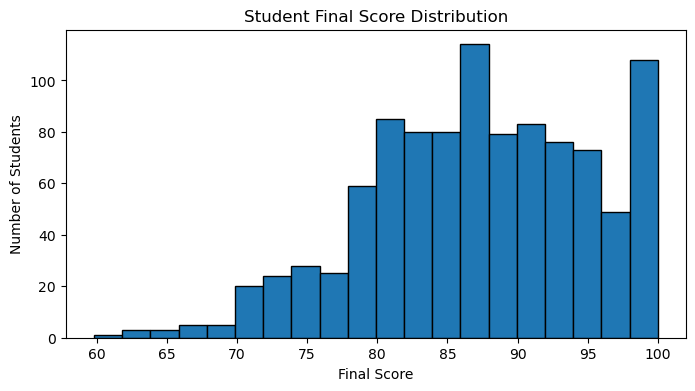

In [11]:
plt.figure(figsize=(8,4))
plt.hist(data["Final_Score"], bins=20, edgecolor="black")
plt.title("Student Final Score Distribution")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.show()

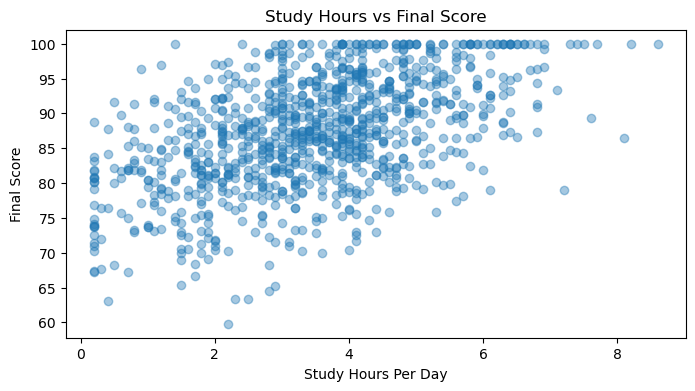

In [12]:
plt.figure(figsize=(8,4))
plt.scatter(data["Study_Hours"], data["Final_Score"], alpha=0.4)
plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Score")
plt.show()

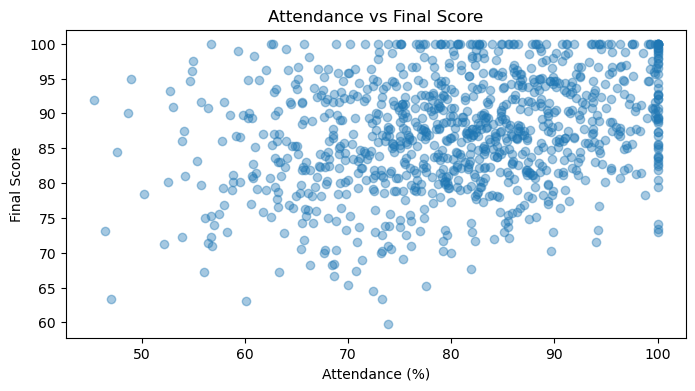

In [13]:
plt.figure(figsize=(8,4))
plt.scatter(data["Attendance"], data["Final_Score"], alpha=0.4)
plt.title("Attendance vs Final Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Score")
plt.show()

## 4. Train and evaluate Linear Regression

In [15]:
X = data[["Study_Hours", "Attendance", "Previous_Score", "Sleep_Hours", "Assignment_Average", "Practice_Tests"]]
y = data["Final_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", mean_squared_error(y_test, predictions)**0.5)
print("R2:", r2_score(y_test, predictions))

MAE: 4.087075791118117
RMSE: 5.083704599556364
R2: 0.6121590843318692


In [16]:
joblib.dump(model, "student_model.pkl")
print("Model saved as student_model.pkl")

Model saved as student_model.pkl


## 5. Predict a new student score

In [17]:
new_student = pd.DataFrame([[4, 85, 70, 7, 80, 4]], columns=X.columns)
predicted_score = model.predict(new_student)[0]
print(f"Predicted final score: {max(0, min(100, predicted_score)):.2f} / 100")

Predicted final score: 90.97 / 100


## 6. Run Streamlit app\nRun this in a notebook cell. Streamlit will print a local URL. If the command does not keep the app running in your notebook environment, open a terminal in this same folder and run `streamlit run app.py`.

In [18]:
!pip install streamlit scikit-learn joblib\n!streamlit run app.py

ERROR: Invalid requirement: 'joblib\\n!streamlit': Expected end or semicolon (after name and no valid version specifier)
    joblib\n!streamlit
          ^
Hint: It looks like a path. File 'joblib\n!streamlit' does not exist.
